### **Disclaimer buat mas-mas asdos**
Notebook ini di*run* melalui Colab sama vs code hihi

In [1]:
import os

# 1. Deteksi environment (Colab vs Lokal/VS Code)
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount('/content/drive')
    base_dir = "/content"
else:
    base_dir = os.getcwd()

# 2. Clone atau Sinkronisasi Repo Github
repo_url = "https://github.com/gacoanphilia/Document-Image-Classification.git"
repo_dir = os.path.join(base_dir, "Document-Image-Classification")

if not os.path.exists(repo_dir):
    print("Mengunduh repo baru (Clone)...")
    !git clone {repo_url}
else:
    print("Repo ditemukan, menyinkronkan pembaruan (Pull)...")
    %cd {repo_dir}
    !git pull origin main

# 3. Masuk ke direktori repo
%cd {repo_dir}

# 4. Buat folder 'data'
!mkdir -p data

# 5. Ekstrak data (Hanya jalankan ekstraksi Drive jika berada di Colab)
if IN_COLAB:
    zip_path = "/content/drive/MyDrive/Semester 5/SD4504_SML/Document-Image-Classification/data/document-image-classification-sd234504.zip"
    csv_path = "/content/drive/MyDrive/Semester 5/SD4504_SML/Document-Image-Classification/data/train.csv"

    print("Sedang mengekstrak ZIP ke folder 'data/'... (Mohon tunggu sebentar)")
    !unzip -q -o "{zip_path}" -d data/
    print("Menyalin train.csv...")
    !cp "{csv_path}" data/
else:
    print("Eksekusi Lokal: Pastikan file ZIP dan train.csv sudah berada di dalam folder 'data/'.")

print("Setup Selesai! Berikut isi folder 'data':")
!ls -la data/

MessageError: Error: credential propagation was unsuccessful

In [21]:
import sys
import torch
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from pathlib import Path
from torch.utils.data import DataLoader, random_split, Dataset
from torchvision import transforms, models
import torch.nn as nn
import torch.optim as optim
import torch.cuda.amp as amp
from torchvision.models import EfficientNet_B0_Weights, efficientnet_b0
from tqdm import tqdm
from sklearn.metrics import classification_report, confusion_matrix

sys.path.append(str(Path(".").resolve()))
from scripts.preprocess import DocumentDataset

# Hardware routing otomatis
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Compute Device: {device}")

# Path setup
DATA_DIR = Path("data").resolve()
TRAIN_CSV = DATA_DIR / "train.csv"
IMG_ROOT = DATA_DIR / "train"

Compute Device: cpu


In [16]:
# 1. Definisikan Transformasi Terpisah
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    # Tambahkan augmentasi khusus train di sini jika diperlukan:
    # transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])


# 2. Class Wrapper untuk Menerapkan Transformasi per Subset
class TransformedSubset(Dataset):

  def __init__(self, subset, transform=None):
    self.subset = subset
    self.transform = transform

  def __getitem__(self, idx):
    x, y = self.subset[idx]
    if self.transform:
      x = self.transform(x)
    return x, y

  def __len__(self):
    return len(self.subset)


# 3. Load Raw Dataset (Tanpa Transformasi)
raw_dataset = DocumentDataset(
    csv_file=TRAIN_CSV, data_dir=IMG_ROOT, transform=None
)
print(f"Total valid images loaded: {len(raw_dataset)}")

# 4. Split Dataset 80/20
train_size = int(0.8 * len(raw_dataset))
val_size = len(raw_dataset) - train_size
train_subset, val_subset = random_split(raw_dataset, [train_size, val_size])

# 5. Bungkus Subset dengan Transformasi Masing-Masing
train_dataset = TransformedSubset(train_subset, transform=train_transform)
val_dataset = TransformedSubset(val_subset, transform=val_transform)

# 6. Initialize DataLoaders
use_pin_memory = torch.cuda.is_available()

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2,
    pin_memory=use_pin_memory,
)
val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2,
    pin_memory=use_pin_memory,
)

print(f"Training batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")

Total valid images loaded: 32002
Training batches: 1601
Validation batches: 401


Batch Image Tensor Shape: torch.Size([16, 3, 224, 224])
Batch Label Tensor Shape: torch.Size([16])


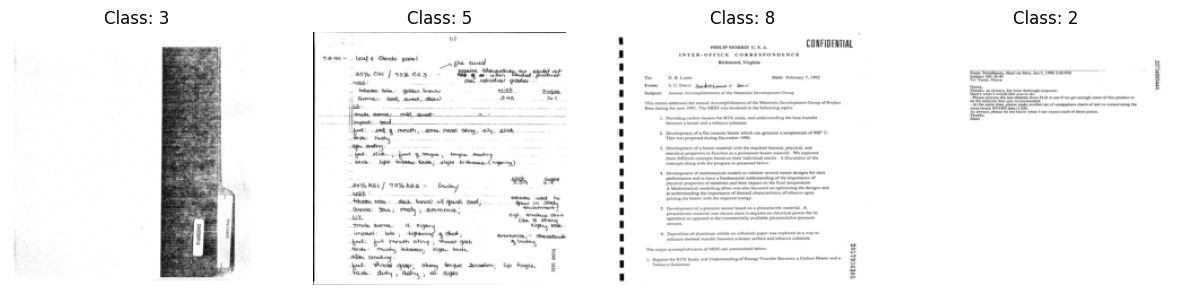

In [20]:
# Grab one batch
images, labels = next(iter(train_loader))

print(f"Batch Image Tensor Shape: {images.shape}") # Should be [16, 3, 224, 224]
print(f"Batch Label Tensor Shape: {labels.shape}") # Should be [16]

# Visualize the first 4 images in the batch (denormalize first for viewing)
def denormalize(tensor):
    tensor = tensor * torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    tensor = tensor + torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    return tensor.clamp(0, 1)

fig, axes = plt.subplots(1, 4, figsize=(15, 5))
for i in range(4):
    img = denormalize(images[i]).permute(1, 2, 0)
    axes[i].imshow(img)
    axes[i].set_title(f"Class: {labels[i].item()}")
    axes[i].axis("off")
plt.show()

In [22]:
# Load pre-trained weights for faster convergence
weights = EfficientNet_B0_Weights.DEFAULT
model = efficientnet_b0(weights=weights)

# Freeze early layers to retain fundamental edge/texture detection
for param in model.features[:5].parameters():
    param.requires_grad = False

# Reconfigure the final classifier for 16 document classes
in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, 16)

model = model.to(device)
print(f"Model loaded and moved to: {device}")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 111MB/s] 


Model loaded and moved to: cpu


In [23]:
# Setup Model Directory (menyasar "root/models/")
MODEL_DIR = Path("..").resolve() / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Tentukan jumlah class (Sesuaikan dengan dataset-mu)
NUM_CLASSES = 16

label_map = {
    0: "advertisement",
    1: "budget",
    2: "email",
    3: "file_folder",
    4: "form",
    5: "handwritten",
    6: "invoice",
    7: "letter",
    8: "memo",
    9: "news_article",
    10: "presentation",
    11: "questionnaire",
    12: "resume",
    13: "scientific_publication",
    14: "scientific_report",
    15: "specification"
}

# Load pre-trained EfficientNet-B0
model = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)

# Modifikasi layer klasifikasi terakhir agar sesuai dengan jumlah class kita
in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, NUM_CLASSES)
model = model.to(device)

# Loss function dan Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

# FIX WARNING: Menggunakan torch.amp.GradScaler sesuai standar PyTorch terbaru
scaler = torch.amp.GradScaler('cuda', enabled=torch.cuda.is_available())

print(f"Model siap! Direktori export: {MODEL_DIR}")

Model siap! Direktori export: /content/models


In [24]:
BEST_MODEL_PATH = MODEL_DIR / "best_model.pth"
TOTAL_EPOCHS = 15  # Batas atas yang lebih fleksibel
PATIENCE = 3  # Hentikan jika val loss tidak membaik selama 3 epoch berturut-turut

best_val_loss = float('inf')
patience_counter = 0

# Dictionary untuk merekam jejak per epoch (sangat berguna untuk plotting nanti)
history = {
    'train_loss': [],
    'val_loss': [],
    'train_acc': [],
    'val_acc': [],
}

# Inisialisasi Learning Rate Scheduler
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=2
)

print(
    f"[INFO] Memulai training (Maks {TOTAL_EPOCHS} Epochs, Patience={PATIENCE}) dengan GPU..."
)

for epoch in range(TOTAL_EPOCHS):
  print(f"\nEpoch {epoch+1}/{TOTAL_EPOCHS}")

  # --- TRAINING PHASE ---
  model.train()
  train_loss = 0.0
  correct_train = 0
  total_train = 0

  train_bar = tqdm(train_loader, desc="Training", leave=False)
  for images, labels in train_bar:
    images, labels = images.to(device), labels.to(device)

    optimizer.zero_grad()

    with torch.autocast(
        device_type=device.type, enabled=torch.cuda.is_available()
    ):
      outputs = model(images)
      loss = criterion(outputs, labels)

    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()

    train_loss += loss.item() * images.size(0)
    _, predicted = torch.max(outputs, 1)
    total_train += labels.size(0)
    correct_train += (predicted == labels).sum().item()

    train_bar.set_postfix({'loss': f'{loss.item():.4f}'})

  epoch_train_loss = train_loss / total_train
  epoch_train_acc = correct_train / total_train

  # --- VALIDATION PHASE ---
  model.eval()
  val_loss = 0.0
  correct_val = 0
  total_val = 0

  val_bar = tqdm(val_loader, desc="Validation", leave=False)
  with torch.no_grad():
    for images, labels in val_bar:
      images, labels = images.to(device), labels.to(device)

      with torch.autocast(
          device_type=device.type, enabled=torch.cuda.is_available()
      ):
        outputs = model(images)
        loss = criterion(outputs, labels)

      val_loss += loss.item() * images.size(0)
      _, predicted = torch.max(outputs, 1)
      total_val += labels.size(0)
      correct_val += (predicted == labels).sum().item()

  epoch_val_loss = val_loss / total_val
  epoch_val_acc = correct_val / total_val

  # Catat ke history
  history['train_loss'].append(epoch_train_loss)
  history['val_loss'].append(epoch_val_loss)
  history['train_acc'].append(epoch_train_acc)
  history['val_acc'].append(epoch_val_acc)

  print(f'Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.4f}')
  print(f'Val Loss:   {epoch_val_loss:.4f} | Val Acc:   {epoch_val_acc:.4f}')

  # Evaluasi scheduler
  scheduler.step(epoch_val_loss)

  # --- EARLY STOPPING & SAVE BEST MODEL ---
  if epoch_val_loss < best_val_loss:
    best_val_loss = epoch_val_loss
    patience_counter = 0  # Reset counter saat ada rekor baru
    torch.save(model.state_dict(), BEST_MODEL_PATH)
    print(
        f'--> Valid loss menurun! Best model diperbarui dan disimpan ke:'
        f' {BEST_MODEL_PATH}'
    )
  else:
    patience_counter += 1
    print(
        '--> Valid loss tidak membaik'
        f' ({patience_counter}/{PATIENCE} epoch stagnan)'
    )
    if patience_counter >= PATIENCE:
      print(
          f'\n[EARLY STOPPING] Pelatihan dihentikan otomatis pada Epoch'
          f' {epoch+1} karena tidak ada penurunan val loss selama {PATIENCE}'
          ' epoch.'
      )
      break

print('\n[INFO] Training Selesai!')

[INFO] Memulai training (Maks 15 Epochs, Patience=3) dengan GPU...

Epoch 1/15


KeyboardInterrupt: 

[INFO] Mengevaluasi model pada data validasi...


Evaluating: 100%|██████████| 401/401 [00:58<00:00,  6.89it/s]



📄 CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.87      0.89      0.88       380
           1       0.73      0.81      0.77       385
           2       0.99      0.98      0.98       399
           3       0.87      0.92      0.89       399
           4       0.71      0.57      0.64       376
           5       0.83      0.95      0.89       424
           6       0.82      0.85      0.83       395
           7       0.84      0.82      0.83       385
           8       0.91      0.85      0.88       388
           9       0.85      0.81      0.83       422
          10       0.67      0.75      0.71       378
          11       0.86      0.66      0.75       434
          12       0.95      0.90      0.93       393
          13       0.88      0.86      0.87       427
          14       0.61      0.67      0.64       399
          15       0.81      0.88      0.84       417

    accuracy                           0.82      6401
 

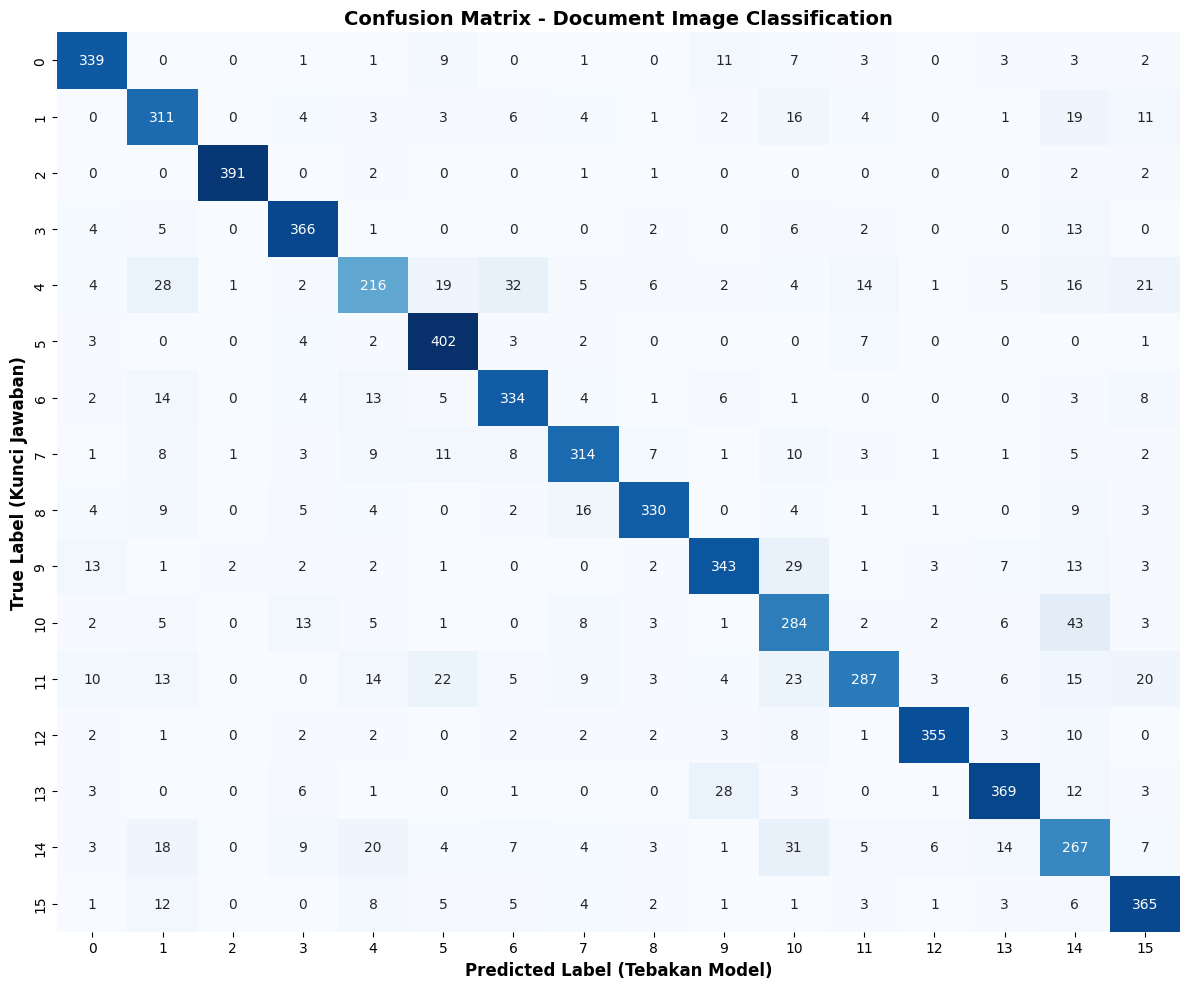

In [ ]:
# 1. Pastikan model memuat bobot terbaik (dari Epoch 4)
# Menggunakan path relative karena kita sudah di dalam root repo
BEST_MODEL_PATH = "/content/models/best_model.pth"
model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
model.eval()

all_preds = []
all_labels = []

print("[INFO] Mengevaluasi model pada data validasi...")
val_bar = tqdm(val_loader, desc="Evaluating")

# 2. Proses Inferensi (Tanpa update bobot)
with torch.no_grad():
    for images, labels in val_bar:
        images = images.to(device)
        # Gunakan autocast agar inferensi juga cepat seperti saat training
        with torch.autocast(device_type=device.type, enabled=torch.cuda.is_available()):
            outputs = model(images)
            _, preds = torch.max(outputs, 1)

        # Pindahkan hasil dari GPU ke CPU, lalu ubah ke array Numpy
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# (Opsional) Jika dataset kustommu memiliki atribut mapping label ke nama kelas,
# kamu bisa mendefinisikannya di sini agar outputnya berupa teks (misal: 'Invoice', 'Memo'), bukan angka 0,1,2.
# class_names = [nama untuk nama in target_classes]

print("\n" + "="*60)
print("📄 CLASSIFICATION REPORT")
print("="*60)
# Hapus parameter target_names jika kamu belum punya list nama kelasnya
print(classification_report(all_labels, all_preds))

print("\n" + "="*60)
print("📊 CONFUSION MATRIX")
print("="*60)

# 3. Visualisasi Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(12, 10)) # Ukuran diperbesar agar angka tidak bertumpuk jika kelasnya banyak
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted Label (Tebakan Model)', fontsize=12, fontweight='bold')
plt.ylabel('True Label (Kunci Jawaban)', fontsize=12, fontweight='bold')
plt.title('Confusion Matrix - Document Image Classification', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

[INFO] Melacak dokumen Kelas 14 yang disalahartikan sebagai Kelas 10...


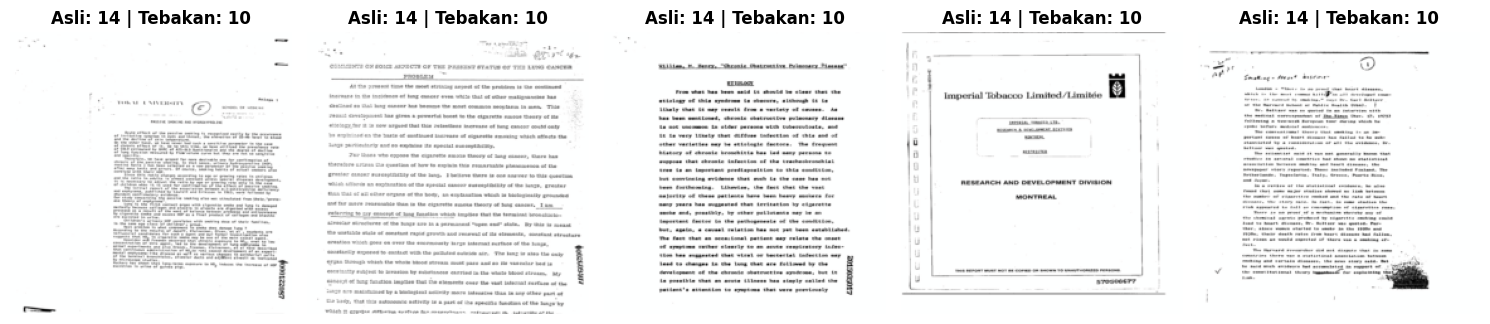

In [ ]:
# Pastikan model dalam mode evaluasi
model.eval()

# Fokus pada kesalahan terbesar di Confusion Matrix:
TARGET_TRUE = 14
TARGET_PRED = 10
misclassified_images = []

print(f"[INFO] Melacak dokumen Kelas {TARGET_TRUE} yang disalahartikan sebagai Kelas {TARGET_PRED}...")

with torch.no_grad():
    # Iterasi langsung ke val_dataset (bukan val_loader) agar mudah menarik gambarnya tunggal
    for i in range(len(val_dataset)):
        image, label = val_dataset[i]

        if label == TARGET_TRUE:
            # Tambahkan batch dimension [C, H, W] -> [1, C, H, W]
            img_tensor = image.unsqueeze(0).to(device)

            with torch.autocast(device_type=device.type, enabled=torch.cuda.is_available()):
                output = model(img_tensor)
                _, pred = torch.max(output, 1)

            if pred.item() == TARGET_PRED:
                misclassified_images.append(image)

            # Tarik 5 sampel saja agar visualisasi rapi
            if len(misclassified_images) >= 5:
                break

if misclassified_images:
    fig, axes = plt.subplots(1, len(misclassified_images), figsize=(15, 5))
    if len(misclassified_images) == 1: axes = [axes]

    for ax, img in zip(axes, misclassified_images):
        # Denormalisasi tensor kembali ke format gambar normal RGB
        img = img.numpy().transpose((1, 2, 0))
        mean = np.array([0.485, 0.456, 0.406])
        std = np.array([0.229, 0.224, 0.225])
        img = std * img + mean
        img = np.clip(img, 0, 1)

        ax.imshow(img)
        ax.set_title(f"Asli: {TARGET_TRUE} | Tebakan: {TARGET_PRED}", fontweight='bold')
        ax.axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("Tidak ditemukan misklasifikasi pada sampel awal yang diuji.")